# Chapter 3 — Understanding the original paper

This chapter reconstructs the argument of Adamik et al. (2024) step by step. Statements are tagged **[paper]** when they are the authors' and **[ours]** when they are this project's reading of something the paper leaves open. The complete list of such readings is in `research/reproduction/specification.md`.

In [1]:
# Locate the research/ directory and make the real implementation importable.
import sys, json
from pathlib import Path
RESEARCH = Path.cwd().resolve()
while not (RESEARCH / "pel").is_dir():
    RESEARCH = RESEARCH.parent
for path in (RESEARCH, RESEARCH / "experiments"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
FIGURES = RESEARCH / "experiments" / "figures"
RESULTS = RESEARCH / "experiments" / "results"
%matplotlib inline

## 3.1 Problem formulation

**[paper, Sec. 3.1]** A robot $r$ has sensors $S^r$. The world is in some state $x \in \mathcal{X}$ containing entities $E_\mathcal{X}$, which have attributes of types $A$ and stand in relations of types $P$. A sensor $s$ performs an **observation process**

$$f_o^s : \mathcal{X} \to \mathcal{O},$$

which yields a noisy, partial picture of the world: an observation $o$ is just a tensor of real numbers whose shape depends on the sensor (an image, a point cloud, an audio buffer).

The task is then split into three functions:

| Function | Name | Input → output | In the baseline |
|---|---|---|---|
| $f_o$ | observation | world → sensor data | the hardware; not studied |
| $f_r$ | recognition | sensor data → **observation graph** $G_o$ | YOLO object detector |
| $f_m$ | mapping | $G_o \times G_t$ → linked graph $G_l$ | candidate selection $f_c$ + disambiguation $f_d$ |

**Where the idea comes from [paper, Sec. 3.2, Fig. 3].** Besl & Jain (1985) described object recognition as *description* (extract symbolic features from sensor data) followed by *understanding* (match the description against a world model). The paper's key move is to observe that a public knowledge graph can play the role of the world model. Modern detectors hide the world model inside network weights; PEL makes it external, inspectable and shared.

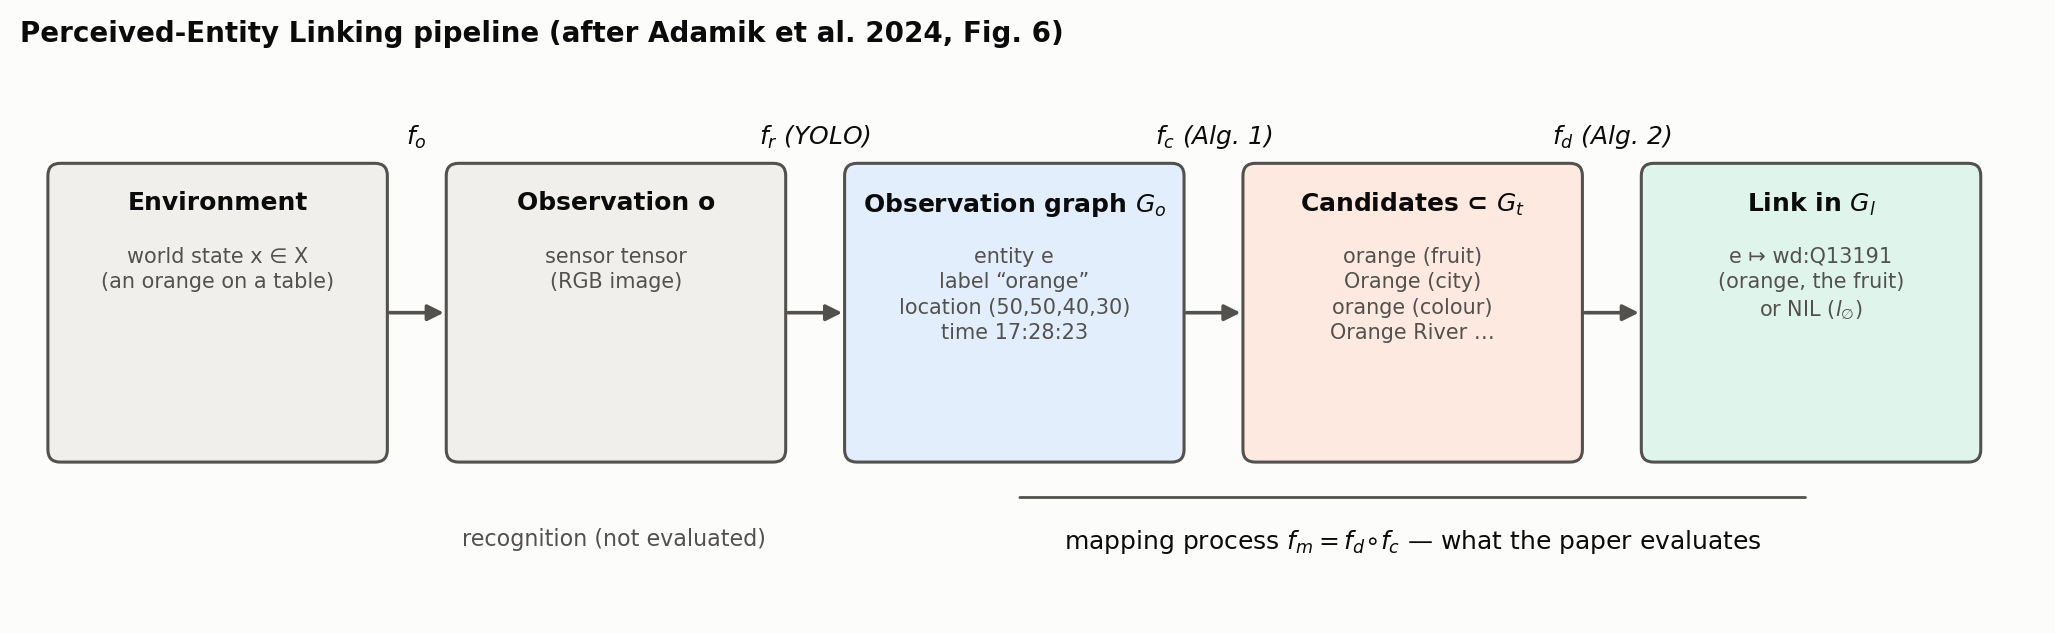

In [2]:
from IPython.display import Image
Image(filename=str(FIGURES / "concepts" / "pel_pipeline.png"), width=950)

## 3.2 The observation graph

**[paper]** The output of recognition is a set of triples

$$G_o \subseteq E_o \times P \times (E_o \cup A).$$

Each perceived entity $e \in E_o$ has a label literal $l_e$ and is *grounded* by a location $a_e^{loc} \in \mathbb{R}^n$ and a time $a_e^{time} \in \mathbb{R}$. The location is deliberately general — a bounding box, a segmentation mask, or the whole image for a classifier.

In code this is `pel/observation_graph.py`:

In [3]:
from pel.observation_graph import from_detections
graph = from_detections([("orange", (50, 50, 40, 30), 0.95), ("couch", (200, 80, 300, 160), 0.71)], time=62903.0)
for triple in graph.triples():
    print(triple)

('entity_1', 'hasLabel', 'orange')
('entity_1', 'hasLocation', (50.0, 50.0, 40.0, 30.0))
('entity_1', 'hasTime', 62903.0)
('entity_1', 'hasCertainty', 0.95)
('entity_2', 'hasLabel', 'couch')
('entity_2', 'hasLocation', (200.0, 80.0, 300.0, 160.0))
('entity_2', 'hasTime', 62903.0)
('entity_2', 'hasCertainty', 0.71)


## 3.3 The mapping process

**[paper]** $f_m : G_o \times G_t \to G_l$ maps every perceived entity to its corresponding entity in the target graph, or to the NIL symbol $l_\emptyset$ when the graph has none.

**[ours]** Two observations about this definition. First, the baseline uses only the label $l_e$; location, time and neighbouring entities are carried along but unused. Second, the baseline has no step that *decides* for $l_\emptyset$ — NIL arises only when a query returns nothing. Both are stated as future work in the paper.

### Three motivating scenarios [paper, Sec. 3.3]

| Scenario | Target | Status in the paper |
|---|---|---|
| Perceived-Entity **Typing** | the *class* the label denotes, ideally a finer one (armchair vs. office chair) | **what the baseline addresses** |
| Perceived-Entity **Recognition** | a known *individual* (Anna's favourite cup) | future work |
| **Attribute-based** typing | a class inferred from colour/size/shape when no label is available | future work |

Keep the first row in mind: *the target is a class*. Chapter 7 shows that the baseline's disambiguation rule does not respect this.

## 3.4 The proposed solution

### Candidate selection $f_c$ — Algorithm 1 [paper, Sec. 4.1]

*Motivation:* the label may not be the string the graph uses. *Mechanism:* take every WordNet synset of the label, collect all their lemma names, score each name by Levenshtein similarity to the label, sort, and query the graph with each name. All returned entities are candidates.

In [4]:
from pel.candidate_selection import select_candidate_names
for label in ("orange", "couch", "sports ball"):
    print(label, "->", [(round(score, 2), name) for score, name in select_candidate_names(label)])

orange -> [(1.0, 'orange'), (0.83, 'Orange'), (0.62, 'orangish'), (0.6, 'orangeness'), (0.55, 'orange tree'), (0.42, 'Orange River')]
couch -> [(1.0, 'couch'), (0.33, 'lounge'), (0.2, 'sofa'), (0.2, 'cast'), (0.2, 'put'), (0.17, 'redact'), (0.0, 'frame')]
sports ball -> [(1.0, 'sports ball')]


Three behaviours are visible already:

* `orange` gains `orange tree`, `Orange River`, `orangish` — synonyms of *other senses* of the word.
* `couch` gains `sofa` and `lounge` (good) but also `put`, `redact`, `cast`, `frame` — WordNet lists “couch” as a verb (“to couch a request in polite terms”). **[ours]** The algorithm does not filter by part of speech.
* `sports ball` is unknown to WordNet, so the label itself is the only name [paper, Alg. 1, lines 4–6].

### Disambiguation $f_d$ — Algorithm 2 [paper, Sec. 4.2]

*Motivation:* “the prior importance of entities that correspond to physical entities should be considerably higher than that of abstract entities.” *Mechanism:* look up each candidate's **classes** in the graph, find the WordNet synsets of the class labels, and score the candidate by the highest path similarity between any class synset and any synset of the perceived label. Sort by score.

$$\mathrm{score}(c) = \max_{k \in \mathrm{Cls}(c)}\; \max_{s \in \mathrm{Syn}(k)}\; \max_{t \in \mathrm{Syn}(l)}\; \mathrm{sim}_{path}(s, t)$$

The orange (fruit) is a subclass of *citrus fruit*; `citrus` is the direct hypernym of `orange.n.01`, so its score is ½. A candidate whose class label is not a WordNet entry at all (*eye color*, *city in the United States*) scores 0. Chapter 4 computes the scores for the real candidates — and shows that the fruit does not win as clearly as this sketch suggests.

### The alternatives the authors mention

**[paper, Sec. 4.2]** Disambiguation could instead use *commonness* (the most common-sense answer), *coherence* with other entities already linked in the same observation, or *attributes* provided by recognition. The baseline implements the class-similarity ranking only; commonness appears separately, as the `_links` ordering of the queries. **[ours]** The two signals are never combined — a point taken up in Chapter 8.

## 3.5 Evaluation methodology [paper, Sec. 5]

* **Labels:** the 80 MS COCO categories; and Visual Genome object synsets.
* **Target graphs:** WikiData, DBpedia, YAGO.
* **Conditions:** 4 query types × 3 processes — $f_q$ (query only), $f_c$, $f_c + f_d$.
* **Ground truth:** COCO by manual search (close alternatives allowed, e.g. *ball* for `sports ball`); Visual Genome automatically: synset → WikiData via the property “WordNet 3.1 Synset ID” (P8814) → DBpedia/YAGO via `owl:sameAs`; only synsets present in all three graphs are kept (2,399).
* **Metric:** hit@1 (accuracy), hit@3, hit@5.
* **External baselines:** DBpedia Spotlight (0.525 on COCO) and AIDA (no hits).

## 3.6 What the paper claims — and how strongly

**[paper]** The conclusion is careful: the pipeline “results in some performance increases”, the results “establish a benchmark”, and “a more sophisticated approach … could be investigated”. Table 1 itself shows $f_c$ or $f_d$ *lowering* accuracy in a number of cells.

**[ours]** So the paper's durable contributions are the **task definition** and the **benchmark protocol**; the baseline method is explicitly a first attempt. That framing matters for how the reproduction should be judged: matching the *behaviour* of the baseline (which signals help where) is more meaningful than matching individual numbers, which depend on live graphs that have changed since 2024.

## 3.7 Where the paper is silent **[ours]**

Implementing the method required ten decisions the paper does not specify. The most consequential:

| # | Open point | Decision here | Why |
|---|---|---|---|
| I1 | how per-name query results are merged | concatenate by name similarity (S, L); sort the pooled set by links (`_links`) | the only reading that keeps each query's ordering rule for the pooled set |
| I2 | edit distance → similarity | $1 - \mathrm{lev}/\max(\lvert a\rvert,\lvert b\rvert)$ | standard normalisation |
| I3 | label casing | capitalise for DBpedia and YAGO, not for WikiData | their labels are Wikipedia titles; without it almost nothing matches |
| I4 | result limit of a query | 50 | unspecified |
| I6 | what a candidate's “class” is | `instance of`/`subclass of` (WikiData), `rdf:type`/`rdfs:subClassOf` (others) | closest standard notion |
| I8 | denominator of accuracy | all labels | the paper reports “55 out of the 80 labels” |

**Next:** Chapter 4 works through the mathematics with numbers.